# Blockchain-based AI Training Provenance System — Evaluation Notebook

This notebook covers all evaluation criteria from the research Evaluation Plan:

| # | Criterion | Target |
|---|-----------|--------|
| 1 | Training performance overhead | < 5% wall-clock increase |
| 2 | Audit effectiveness | 100% tampering detection rate |
| 3 | Verification response | One-click to result delay < 2 s |
| 4 | Storage scalability | - Off-chain storage linear growth: R² > 0.99 <br>- On-chain gas consumption: Linear growth, no explosion |
| 5 | Atomic consistency & fault recovery | 100% recovery, 0 duplicates |
| 6 | Audit coverage | Step coverage ratio = 1.0, Epoch coverage ratio = 1.0 |

**Prerequisites**
- Audit controller running on `CONTROLLER_URL`
- Prometheus scraping audit controller on `PROMETHEUS_URL`
- One completed training session (SESSION_ID filled in Section 0)
- `NODE_ENV` ≠ `production` (tamper & debug endpoints enabled)

## 0. Configuration & Dependencies

In [166]:
!uv add requests pandas matplotlib scipy numpy
!uv sync

Resolved 70 packages in 21ms
Checked 66 packages in 33ms
Resolved 70 packages in 8ms
Checked 67 packages in 2ms


Run AI training with auditing disabled:

In [205]:
ROUND = 5

In [206]:
import os
import subprocess as sp
import time
from pathlib import Path

CWD = Path.cwd()
TOP_DIR = (CWD / '..').resolve()

os.chdir(f'{TOP_DIR}/ai-training')

process_env = os.environ.copy()
process_env['NO_AUDIT']='1'
CONTROL_TIMES = []
for i in range(ROUND):
    start_ts = time.time()
    sp.run(['python', 'trainer.py'], env=process_env)
    end_ts = time.time()
    CONTROL_TIMES.append(end_ts - start_ts)

os.chdir(CWD)


Loading and downloading (if necessary) MNIST dataset to /Users/andy/Documents/GitHub/capstone-project/ai-training/data...
Dataset loaded successfully.
Train Epoch: 1 [0/60000 (0%)]	Loss: 2.295266
Train Epoch: 1 [6400/60000 (11%)]	Loss: 1.815114
Train Epoch: 1 [12800/60000 (21%)]	Loss: 1.234617
Train Epoch: 1 [19200/60000 (32%)]	Loss: 1.008385
Train Epoch: 1 [25600/60000 (43%)]	Loss: 0.774314
Train Epoch: 1 [32000/60000 (53%)]	Loss: 0.606193
Train Epoch: 1 [38400/60000 (64%)]	Loss: 0.409299
Train Epoch: 1 [44800/60000 (75%)]	Loss: 0.800994
Train Epoch: 1 [51200/60000 (85%)]	Loss: 0.419068
Train Epoch: 1 [57600/60000 (96%)]	Loss: 0.511947

Test set: Average loss: 0.1914, Accuracy: 9443/10000 (94.43%)

Train Epoch: 2 [0/60000 (0%)]	Loss: 0.474255
Train Epoch: 2 [6400/60000 (11%)]	Loss: 0.418975
Train Epoch: 2 [12800/60000 (21%)]	Loss: 0.601930
Train Epoch: 2 [19200/60000 (32%)]	Loss: 0.297634
Train Epoch: 2 [25600/60000 (43%)]	Loss: 0.314913
Train Epoch: 2 [32000/60000 (53%)]	Loss: 0.5360

Run AI training with auditing enabled:

In [207]:
import re

os.chdir(f'{TOP_DIR}/ai-training')

AUDIT_TIMES = []
SESSION_ID = None
TRAIN_START_TS = None
TRAIN_END_TS = None

for i in range(ROUND):
    start_ts = time.time()
    if i == ROUND - 1:
        TRAIN_START_TS = start_ts
    output = sp.check_output(['python', 'trainer.py']).decode('utf-8').strip()
    end_ts = time.time()
    if i == ROUND - 1:
        TRAIN_END_TS = end_ts
        matched = re.search(r'Start Session: (.*)', output)
        if matched:
            SESSION_ID = matched.group(1)
    AUDIT_TIMES.append(end_ts - start_ts)


os.chdir(CWD)

Create global evaluation configuration:

In [208]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
import time
import json
import random

CONTROLLER_URL  = "http://localhost:3000"
PROMETHEUS_URL  = "http://localhost:9090"

# Plot style
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 11,
    'axes.titlesize': 12,
    'axes.labelsize': 11,
    'figure.dpi': 150,
})
COLORS = ['#4C72B0', '#DD8452', '#55A868', '#C44E52', '#8172B2']

def prom_query(promql):
    r = requests.get(f"{PROMETHEUS_URL}/api/v1/query",
                     params={"query": promql}, timeout=10)
    r.raise_for_status()
    return r.json()["data"]["result"]

def prom_range(promql, start, end, step="15s"):
    r = requests.get(f"{PROMETHEUS_URL}/api/v1/query_range",
                     params={"query": promql, "start": start,
                             "end": end, "step": step}, timeout=10)
    r.raise_for_status()
    return r.json()["data"]["result"]

def ctrl(path, method="GET", **kwargs):
    fn = getattr(requests, method.lower())
    timeout = kwargs.pop("timeout", 30)
    r = fn(f"{CONTROLLER_URL}{path}", timeout=timeout, **kwargs)
    r.raise_for_status()
    return r.json()

def random_hex(n=64):
    return ''.join(random.choices('0123456789abcdef', k=n))

def derive_entry_id(session_id, ptype, action_or_id):
    """Mirror of deriveEntryId() in strings.js"""
    if ptype == 'session':
        return f"{session_id}-{action_or_id}"
    elif ptype in ('epoch', 'step'):
        return f"{session_id}-{ptype}-{action_or_id}"
    raise ValueError(f"Unknown packet type: {ptype}")

print("Configuration loaded.")
print(f"  Controller : {CONTROLLER_URL}")
print(f"  Prometheus : {PROMETHEUS_URL}")
print(f"  Session ID : {SESSION_ID}")

Configuration loaded.
  Controller : http://localhost:3000
  Prometheus : http://localhost:9090
  Session ID : session-1778931083-836e067c


## 1. Training Performance Overhead (RQ1)

**Method**: Paired-sample comparison of wall-clock training time with and without audit enabled.  
**Target**: Overhead < 5%

In [209]:
# ── Validate inputs ───────────────────────────────────────────────────────────
assert all(t is not None for t in CONTROL_TIMES), \
    "Fill CONTROL_TIMES with 3 wall-clock values (seconds) from `time` command"
assert all(t is not None for t in AUDIT_TIMES), \
    "Fill AUDIT_TIMES with 3 wall-clock values (seconds) from `time` command"

ctrl_arr  = np.array(CONTROL_TIMES, dtype=float)
audit_arr = np.array(AUDIT_TIMES,   dtype=float)

ctrl_mean,  ctrl_std  = ctrl_arr.mean(),  ctrl_arr.std(ddof=1)
audit_mean, audit_std = audit_arr.mean(), audit_arr.std(ddof=1)
overhead_pct = (audit_mean - ctrl_mean) / ctrl_mean * 100
t_stat, p_value = stats.ttest_ind(ctrl_arr, audit_arr)

print(f"Control  : {ctrl_mean:.1f}s  ± {ctrl_std:.1f}s")
print(f"Audit    : {audit_mean:.1f}s  ± {audit_std:.1f}s")
print(f"Overhead : {overhead_pct:+.2f}%  (target < 5%)")
print(f"t-test   : t={t_stat:.3f}, p={p_value:.4f}")
print(f"Result   : {'PASS ✓' if overhead_pct < 5 else 'FAIL ✗'}")

Control  : 193.1s  ± 6.4s
Audit    : 201.7s  ± 4.1s
Overhead : +4.48%  (target < 5%)
t-test   : t=-2.535, p=0.0350
Result   : PASS ✓


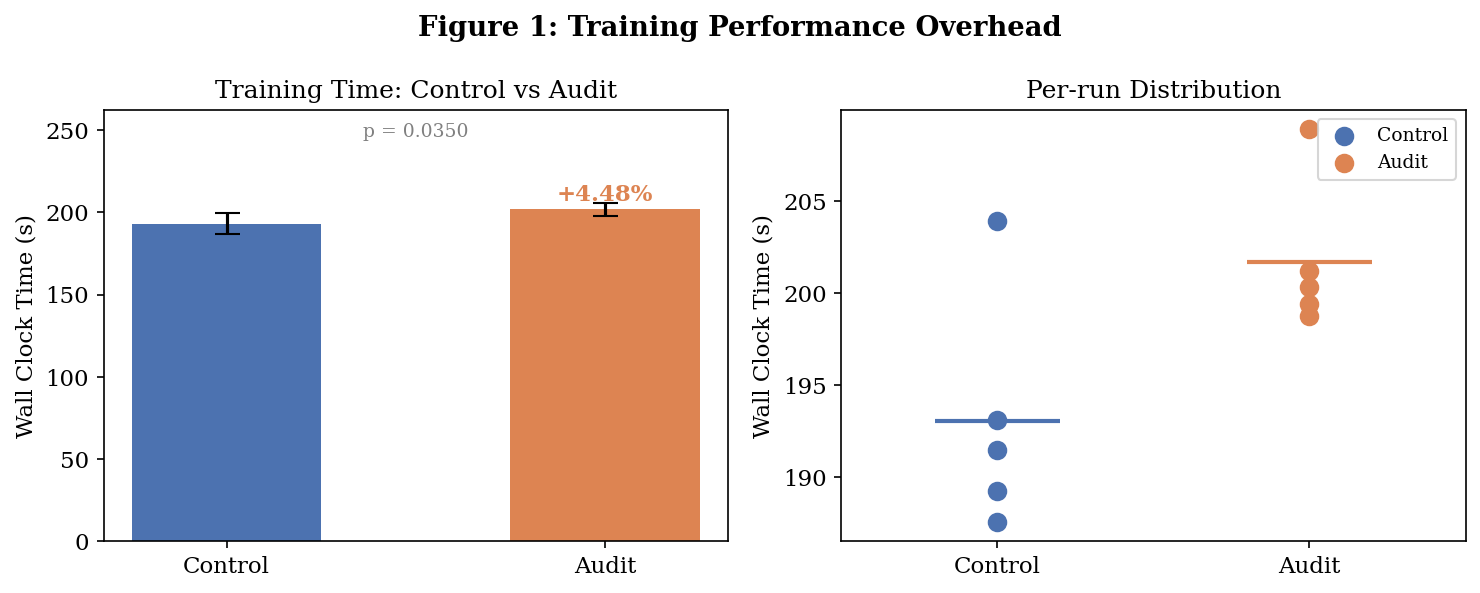

In [234]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Left: grouped bar with error bars
ax = axes[0]
ax.bar(["Control", "Audit"], [ctrl_mean, audit_mean],
       yerr=[ctrl_std, audit_std], capsize=6,
       color=COLORS[:2], width=0.5,
       error_kw={"linewidth": 1.5})
ax.set_ylabel("Wall Clock Time (s)")
ax.set_title("Training Time: Control vs Audit")
ax.set_ylim(0, max(ctrl_mean, audit_mean) * 1.3)
ax.annotate(f"{overhead_pct:+.2f}%",
            xy=(1, audit_mean + audit_std + 1),
            ha="center", fontsize=11,
            color=COLORS[1], fontweight="bold")
ax.text(0.5, 0.97, f"p = {p_value:.4f}",
        transform=ax.transAxes, ha="center", va="top",
        fontsize=9, color="gray")

# Right: per-run scatter
ax2 = axes[1]
ax2.scatter([0]*ROUND, ctrl_arr,  color=COLORS[0], s=70, zorder=3, label="Control")
ax2.scatter([1]*ROUND, audit_arr, color=COLORS[1], s=70, zorder=3, label="Audit")
ax2.hlines(ctrl_mean,  -0.2, 0.2, colors=COLORS[0], linewidth=2)
ax2.hlines(audit_mean,  0.8, 1.2, colors=COLORS[1], linewidth=2)
ax2.set_xticks([0, 1])
ax2.set_xticklabels(["Control", "Audit"])
ax2.set_ylabel("Wall Clock Time (s)")
ax2.set_title("Per-run Distribution")
ax2.legend(fontsize=9)
ax2.set_xlim(-0.5, 1.5)

fig.suptitle("Figure 1: Training Performance Overhead", fontweight="bold")
plt.tight_layout()
fig.savefig("fig1_overhead.pdf", bbox_inches="tight")
plt.show()

## 2. Audit effectiveness

**Method**: Programmatically tamper OrbitDB records via `/audit/tamper`, then call verify endpoints.  
**Target**: 100% detection rate across all tamper types  

### 2.1 Fetch session packets & a fake CID

In [212]:
packets = ctrl(f"/audit/session/{SESSION_ID}/packets", timeout=300)
steps   = packets["steps"]
epochs  = packets["epochs"]

print(f"Steps  : {len(steps)}")
print(f"Epochs : {len(epochs)}")

assert steps,  "No step packets found — check SESSION_ID"
assert epochs, "No epoch packets found — check SESSION_ID"

# Pick one representative packet of each type for tampering
sample_step  = steps[len(steps) // 2]    # middle step
sample_epoch = epochs[len(epochs) // 2]  # middle epoch

# Derive entry IDs
step_entry_id  = derive_entry_id(SESSION_ID, 'step',    sample_step['step_id'])
epoch_entry_id = derive_entry_id(SESSION_ID, 'epoch',   sample_epoch['epoch'])
sess_start_id  = derive_entry_id(SESSION_ID, 'session', 'start')
sess_end_id    = derive_entry_id(SESSION_ID, 'session', 'end')

print(f"\nStep  entry_id  : {step_entry_id}")
print(f"Epoch entry_id  : {epoch_entry_id}")
print(f"Session start   : {sess_start_id}")
print(f"Session end     : {sess_end_id}")

Steps  : 47
Epochs : 10

Step  entry_id  : session-1778931083-836e067c-step-4800
Epoch entry_id  : session-1778931083-836e067c-epoch-6
Session start   : session-1778931083-836e067c-start
Session end     : session-1778931083-836e067c-end


In [213]:
# Obtain a fake CID — reuse the CID of any existing IPFS file that is NOT
# the one being tested (use a checkpoint CID from a different epoch)
fake_cid = None
for ep in epochs:
    if ep['epoch'] != sample_epoch['epoch'] and ep.get('checkpoint_cid'):
        fake_cid = ep['checkpoint_cid']
        break

assert fake_cid, "Could not find a fake CID — need at least 2 epoch packets"
print(f"Fake CID (from different epoch): {fake_cid}")

Fake CID (from different epoch): bafkreiewivpa5wdmwhksgcglf5snoalrjupgiisihkwmuidjto4gz2yyl4


### 2.2 Tamper & Verify — all scenarios

In [214]:
def tamper(entry_id, tamper_type, fake_cid=None):
    body = {"entry_id": entry_id, "tamper_type": tamper_type}
    if fake_cid:
        body["fake_cid"] = fake_cid
    return ctrl("/debug/tamper", method="POST", json=body)

def get_entry(entry_id):
    return ctrl(f"/debug/entry/{entry_id}")

def restore(entry_id, original_entry):
    return ctrl("/debug/restore", method="POST",
                json={"entry_id": entry_id, "original_entry": original_entry})

def verify_session():
    return ctrl(f"/audit/verify/session/{SESSION_ID}")

def verify_dataset():
    return ctrl(f"/audit/verify/session/{SESSION_ID}/dataset")

def verify_model():
    return ctrl(f"/audit/verify/session/{SESSION_ID}/model")

def verify_checkpoint(epoch_id):
    return ctrl(f"/audit/verify/session/{SESSION_ID}/epoch/{epoch_id}/checkpoint")

def run_tamper_scenario(name, entry_id, tamper_type, verify_fn,
                        expected_field, fake_cid=None):
    """
    1. Tamper the entry
    2. Call the verify endpoint
    3. Record detection result
    Returns dict with scenario name and pass/fail
    """
    print(f"\n{'─'*56}")
    print(f"Scenario : {name}")

    original = get_entry(entry_id)

    tamper(entry_id, tamper_type, fake_cid)
    print(f"  Tampered entry  : {entry_id}  [{tamper_type}]")

    result = verify_fn()
    detected = not result.get(expected_field)
    print(f"  Tamper detected : {'YES ✓' if detected else 'NO ✗'}")

    restore(entry_id, original)
    print(f"  Restored        : {entry_id}")

    return {"scenario": name, "tamper_type": tamper_type,
            "detected": detected, "result": "PASS" if detected else "FAIL"}


tamper_results = []

# ── Scenario 1: step loss value tampering ─────────────────────────────────────
tamper_results.append(run_tamper_scenario(
    name        = "Step loss metric tamper",
    entry_id    = step_entry_id,
    tamper_type = "step_loss",
    verify_fn   = verify_session,
    expected_field = "isValid"
))

# ── Scenario 2: epoch checkpoint_hash tampering ───────────────────────────────
tamper_results.append(run_tamper_scenario(
    name        = "Epoch checkpoint_hash tamper",
    entry_id    = epoch_entry_id,
    tamper_type = "epoch_checkpoint_hash",
    verify_fn   = lambda: verify_checkpoint(sample_epoch['epoch']),
    expected_field = "is_valid"
))

# ── Scenario 3: epoch checkpoint_cid tampering (IPFS pointer) ────────────────
tamper_results.append(run_tamper_scenario(
    name        = "Epoch checkpoint_cid tamper (IPFS pointer)",
    entry_id    = epoch_entry_id,
    tamper_type = "checkpoint_cid",
    verify_fn   = lambda: verify_checkpoint(sample_epoch['epoch']),
    expected_field = "is_valid",
    fake_cid    = fake_cid
))

# ── Scenario 4: dataset_cid tampering (IPFS pointer) ────────────────────────
tamper_results.append(run_tamper_scenario(
    name        = "Session dataset_cid tamper (IPFS pointer)",
    entry_id    = sess_start_id,
    tamper_type = "dataset_cid",
    verify_fn   = verify_dataset,
    expected_field = "is_valid",
    fake_cid    = fake_cid
))

# ── Scenario 5: model_hash tampering ─────────────────────────────────────────
tamper_results.append(run_tamper_scenario(
    name        = "Session model_hash tamper",
    entry_id    = sess_end_id,
    tamper_type = "model_hash",
    verify_fn   = verify_model,
    expected_field = "is_valid"
))

# ── Scenario 6: model_cid tampering (IPFS pointer) ───────────────────────────
tamper_results.append(run_tamper_scenario(
    name        = "Session model_cid tamper (IPFS pointer)",
    entry_id    = sess_end_id,
    tamper_type = "model_cid",
    verify_fn   = verify_model,
    expected_field = "is_valid",
    fake_cid    = fake_cid
))

df_tamper = pd.DataFrame(tamper_results)
detection_rate = df_tamper["detected"].mean() * 100
print(f"\n{'='*55}")
print(df_tamper[["scenario", "tamper_type", "result"]].to_string(index=False))
print(f"\nDetection rate: {detection_rate:.1f}%  (target: 100%)")
print(f"Overall result: {'PASS ✓' if detection_rate == 100 else 'FAIL ✗'}")


────────────────────────────────────────────────────────
Scenario : Step loss metric tamper
  Tampered entry  : session-1778931083-836e067c-step-4800  [step_loss]
  Tamper detected : YES ✓
  Restored        : session-1778931083-836e067c-step-4800

────────────────────────────────────────────────────────
Scenario : Epoch checkpoint_hash tamper
  Tampered entry  : session-1778931083-836e067c-epoch-6  [epoch_checkpoint_hash]
  Tamper detected : YES ✓
  Restored        : session-1778931083-836e067c-epoch-6

────────────────────────────────────────────────────────
Scenario : Epoch checkpoint_cid tamper (IPFS pointer)
  Tampered entry  : session-1778931083-836e067c-epoch-6  [checkpoint_cid]
  Tamper detected : YES ✓
  Restored        : session-1778931083-836e067c-epoch-6

────────────────────────────────────────────────────────
Scenario : Session dataset_cid tamper (IPFS pointer)
  Tampered entry  : session-1778931083-836e067c-start  [dataset_cid]
  Tamper detected : YES ✓
  Restored       

/var/folders/r6/565fgmn902qcpzlfk_wfgycr0000gn/T/ipykernel_75071/1867091872.py:36: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) DejaVu Serif.
  plt.tight_layout()
/var/folders/r6/565fgmn902qcpzlfk_wfgycr0000gn/T/ipykernel_75071/1867091872.py:37: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) DejaVu Serif.
  fig.savefig("fig2_tamper.pdf", bbox_inches="tight")
/Users/andy/Documents/GitHub/capstone-project/.venv/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) DejaVu Serif.
  fig.canvas.print_figure(bytes_io, **kw)


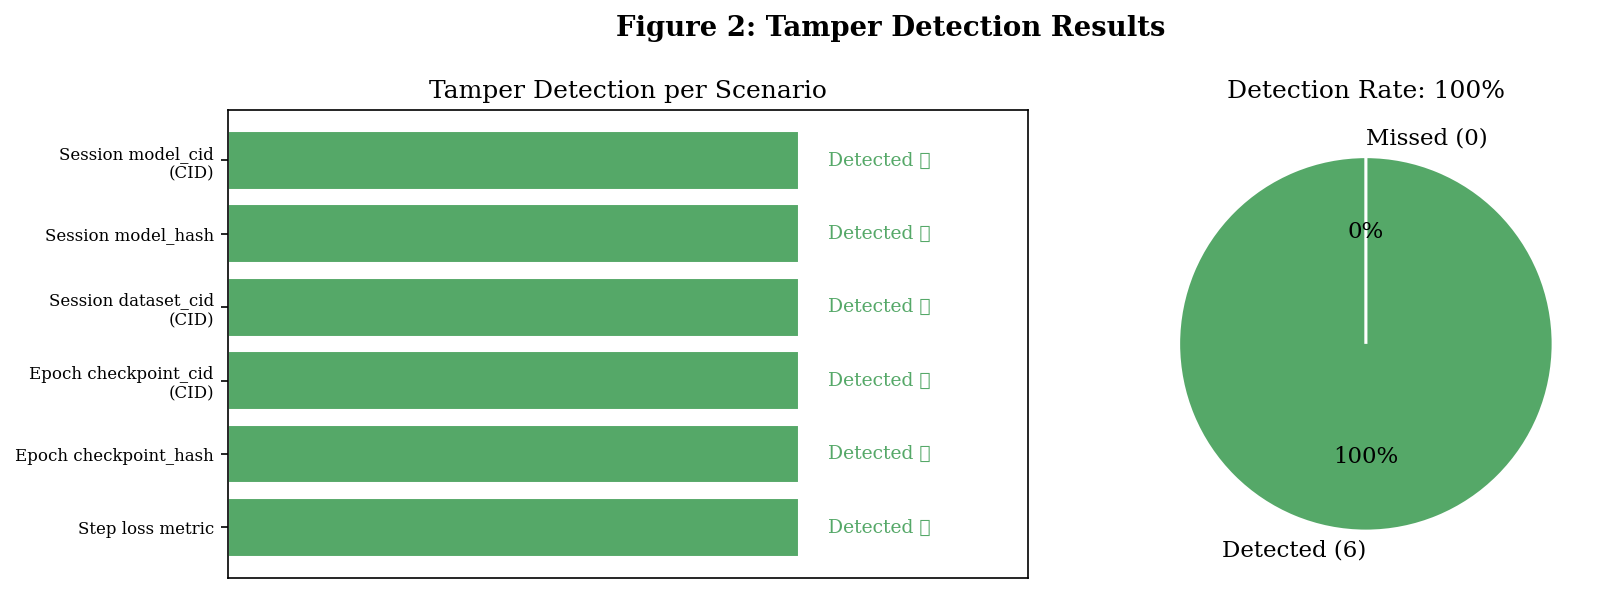

In [235]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Left: per-scenario detection bar
ax    = axes[0]
names = [r["scenario"] for r in tamper_results]
short_names = [
    n.replace(" tamper", "").replace(" (IPFS pointer)", "\n(CID)")
    for n in names
]
colors_bar = [COLORS[2] if r["detected"] else COLORS[3] for r in tamper_results]
ax.barh(range(len(short_names)),
        [1]*len(tamper_results),
        color=colors_bar, edgecolor="white")
ax.set_yticks(range(len(short_names)))
ax.set_yticklabels(short_names, fontsize=8)
ax.set_xlim(0, 1.4)
ax.set_xticks([])
for i, r in enumerate(tamper_results):
    label = "Detected ✓" if r["detected"] else "Missed ✗"
    ax.text(1.05, i, label, va="center", fontsize=9,
            color=COLORS[2] if r["detected"] else COLORS[3])
ax.set_title("Tamper Detection per Scenario")

# Right: summary pie
ax2      = axes[1]
detected = sum(1 for r in tamper_results if r["detected"])
missed   = len(tamper_results) - detected
ax2.pie([detected, missed],
        labels=[f"Detected ({detected})", f"Missed ({missed})"],
        colors=[COLORS[2], COLORS[3]],
        autopct="%1.0f%%", startangle=90,
        wedgeprops={"edgecolor": "white", "linewidth": 1.5})
ax2.set_title(f"Detection Rate: {detection_rate:.0f}%")

fig.suptitle("Figure 2: Tamper Detection Results", fontweight="bold")
plt.tight_layout()
fig.savefig("fig2_tamper.pdf", bbox_inches="tight")
plt.show()

## 3. Verification Response

**Source**: `audit_verify_duration_ms` histogram from Prometheus  
**Target**:  < 2000 ms

In [218]:
import time
time.sleep(20)

SLA_MS = 2000

def percentile_from_buckets(buckets_dict, pct):
    items = sorted(
        [(float(le), cnt) for le, cnt in buckets_dict.items() if le != "+Inf"],
        key=lambda x: x[0]
    )
    total = float(buckets_dict.get("+Inf", items[-1][1] if items else 1))
    target = total * pct / 100
    prev_le, prev_cnt = 0, 0
    for le, cnt in items:
        if cnt >= target:
            frac = (target - prev_cnt) / max(cnt - prev_cnt, 1)
            return prev_le + frac * (le - prev_le)
        prev_le, prev_cnt = le, cnt
    return items[-1][0] if items else 0

verify_types = ["session", "dataset", "model", "checkpoint"]
summary = []

for vtype in verify_types:
    raw = prom_query(
        f'audit_verify_duration_ms_bucket{{verify_type="{vtype}"}}'
    )
    if not raw:
        print(f"No data for verify_type={vtype}")
        continue

    buckets = {r["metric"]["le"]: float(r["value"][1]) for r in raw}
    p50 = percentile_from_buckets(buckets, 50)
    p95 = percentile_from_buckets(buckets, 95)
    p99 = percentile_from_buckets(buckets, 99)
    summary.append({
        "verify_type": vtype,
        "P50 (ms)": round(p50),
        "P95 (ms)": round(p95),
        "P99 (ms)": round(p99),
        "P99 < 2s": "PASS ✓" if p99 < SLA_MS else "FAIL ✗"
    })

df_verify = pd.DataFrame(summary)
print(df_verify.to_string(index=False))

verify_type  P50 (ms)  P95 (ms)  P99 (ms) P99 < 2s
    session       175       242       248   PASS ✓
    dataset       175       242       248   PASS ✓
      model       175       242       248   PASS ✓
 checkpoint       175       242       248   PASS ✓


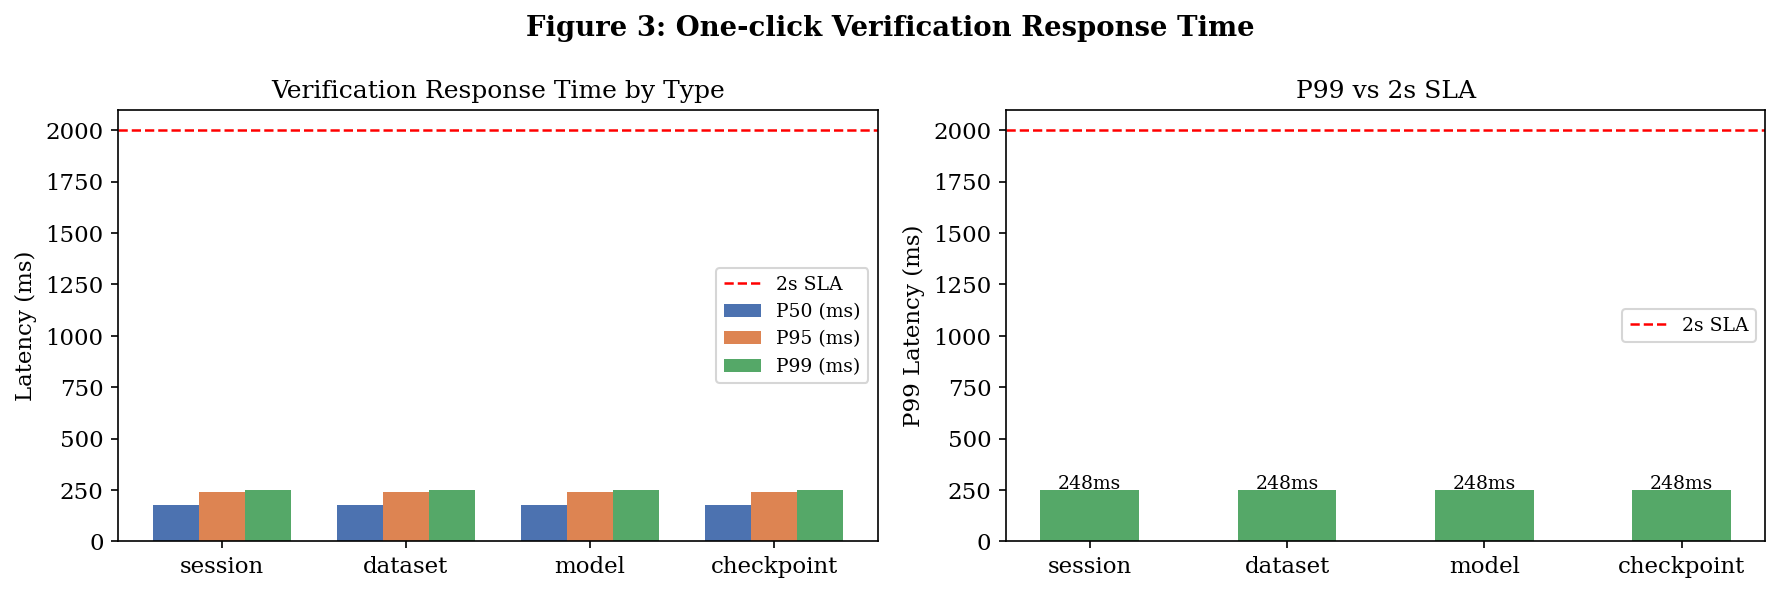

In [236]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Left: The P50/P95/P99 grouped bars for each verify_type
ax = axes[0]
x = np.arange(len(df_verify))
w = 0.25
for j, pct in enumerate(["P50 (ms)", "P95 (ms)", "P99 (ms)"]):
    ax.bar(x + j*w, df_verify[pct], width=w, color=COLORS[j], label=pct)
ax.axhline(SLA_MS, color="red", linestyle="--", linewidth=1.2, label="2s SLA")
ax.set_xticks(x + w)
ax.set_xticklabels(df_verify["verify_type"])
ax.set_ylabel("Latency (ms)")
ax.set_title("Verification Response Time by Type")
ax.legend(fontsize=9)

# Right: P99 vs. SLA
ax2 = axes[1]
colors_bar = [COLORS[2] if v < SLA_MS else COLORS[3]
              for v in df_verify["P99 (ms)"]]
bars = ax2.bar(df_verify["verify_type"], df_verify["P99 (ms)"],
               color=colors_bar, width=0.5)
ax2.axhline(SLA_MS, color="red", linestyle="--",
            linewidth=1.2, label="2s SLA")
for bar, val in zip(bars, df_verify["P99 (ms)"]):
    ax2.text(bar.get_x() + bar.get_width()/2, val + 10,
             f"{val}ms", ha="center", fontsize=9)
ax2.set_ylabel("P99 Latency (ms)")
ax2.set_title("P99 vs 2s SLA")
ax2.legend(fontsize=9)

fig.suptitle("Figure 3: One-click Verification Response Time", fontweight="bold")
plt.tight_layout()
fig.savefig("fig3_verify_latency.pdf", bbox_inches="tight")
plt.show()

## 4. Storage Scalability

### 4.1. Off-chain Storage Linear Growth

- **Source**: timestamps of written events
- **Target**: R² > 0.99 (linear growth, no explosion)

In [220]:
packets  = ctrl(f"/audit/session/{SESSION_ID}/packets",  timeout=60)

# Merge all the timestamps of the written events
all_timestamps = (
    [s["timestamp"] for s in packets["steps"]] +
    [e["timestamp"] for e in packets["epochs"]]
)

# Sort by time and construct the cumulative write curve
all_timestamps.sort()
t0     = pd.Timestamp(all_timestamps[0], tz='UTC').timestamp()
times  = [(pd.Timestamp(ts, tz='UTC').timestamp() - t0) / 60
          for ts in all_timestamps]
counts = list(range(1, len(times) + 1))

slope, intercept, r_value, _, se = stats.linregress(times, counts)
fit       = [slope * t + intercept for t in times]
residuals = [c - f for c, f in zip(counts, fit)]

print(f"Total written events: {len(times)}")
print(f"Linear fit          : entries = {slope:.2f}×t + {intercept:.2f}")
print(f"R²                  : {r_value**2:.5f}  (target > 0.99)")
print(f"Result              : {'PASS ✓' if r_value**2 > 0.99 else 'FAIL ✗'}")

Total written events: 57
Linear fit          : entries = 17.64×t + 0.83
R²                  : 0.99984  (target > 0.99)
Result              : PASS ✓


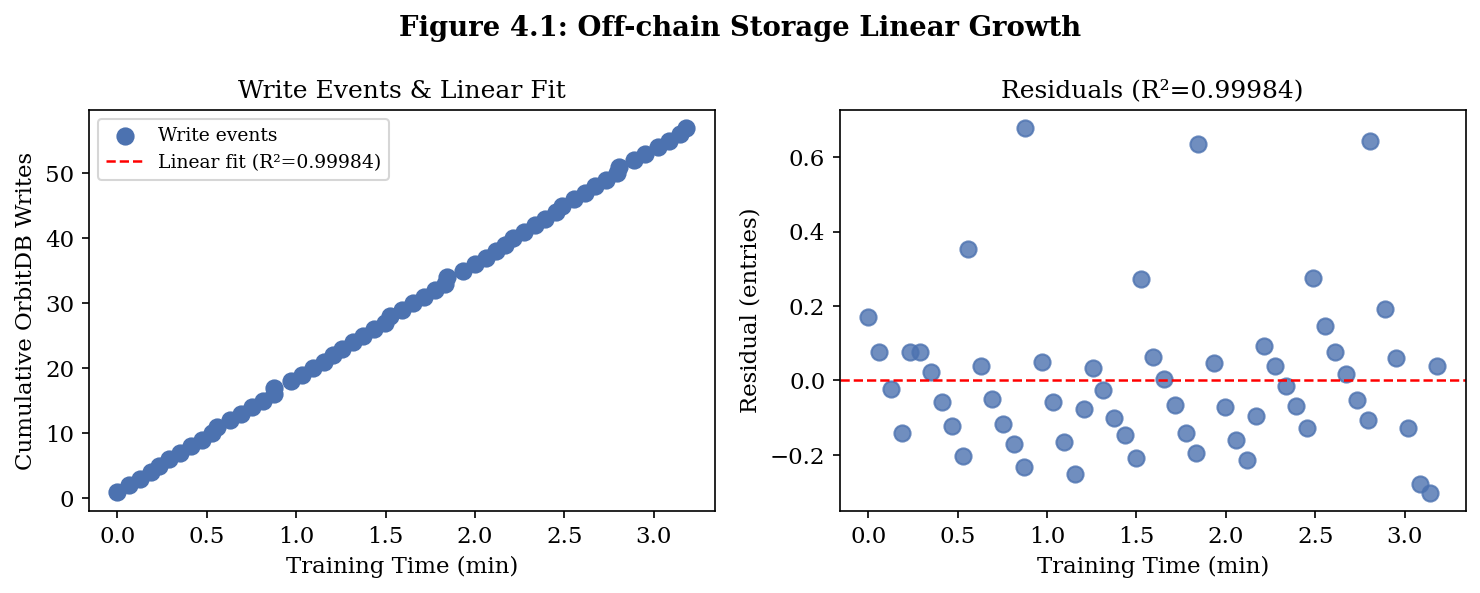

In [238]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Left: linear fitting
ax2 = axes[0]
ax2.scatter(times, counts, color=COLORS[0], s=60,
            zorder=3, label="Write events")
ax2.plot(times, fit, "--", color="red", linewidth=1.2,
         label=f"Linear fit (R²={r_value**2:.5f})")
ax2.set_xlabel("Training Time (min)")
ax2.set_ylabel("Cumulative OrbitDB Writes")
ax2.set_title("Write Events & Linear Fit")
ax2.legend(fontsize=9)

# Right: Residual
ax3 = axes[1]
ax3.scatter(times, residuals, s=60, color=COLORS[0], alpha=0.8)
ax3.axhline(0, color="red", linestyle="--", linewidth=1.2)
ax3.set_xlabel("Training Time (min)")
ax3.set_ylabel("Residual (entries)")
ax3.set_title(f"Residuals (R²={r_value**2:.5f})")

fig.suptitle("Figure 4.1: Off-chain Storage Linear Growth", fontweight="bold")
plt.tight_layout()
fig.savefig("fig4-1_storage.pdf", bbox_inches="tight")
plt.show()

### 4.2 On-chain Gas Consumption

**Source**: `blockchain_gas_used_total` counter by method  
**Target**: Gas grows linearly with iterations, no sudden explosion

In [222]:
methods    = ["startSession", "syncProgress", "completeSession"]
gas_totals = []

for method in methods:
    res = prom_query(
        f'blockchain_gas_used_total{{method="{method}",session_id="{SESSION_ID}"}}'
    )
    total = sum(float(r["value"][1]) for r in res) if res else 0
    gas_totals.append(total)
    print(f"{method:25s}: {total:,.0f} gas")

print(f"\nTotal gas  : {sum(gas_totals):,.0f}")

# Gas per syncProgress call (proxy for per-packet cost)
sync_count_res = prom_query(
    f'audit_packet_ingested_total{{session_id="{SESSION_ID}"}}'
)
sync_count = sum(float(r["value"][1]) for r in sync_count_res) if sync_count_res else 1
avg_gas_per_packet = gas_totals[1] / max(sync_count, 1)
print(f"Avg gas/packet : {avg_gas_per_packet:,.0f}")

startSession             : 69,662 gas
syncProgress             : 1,887,951 gas
completeSession          : 35,221 gas

Total gas  : 1,992,834
Avg gas/packet : 31,999


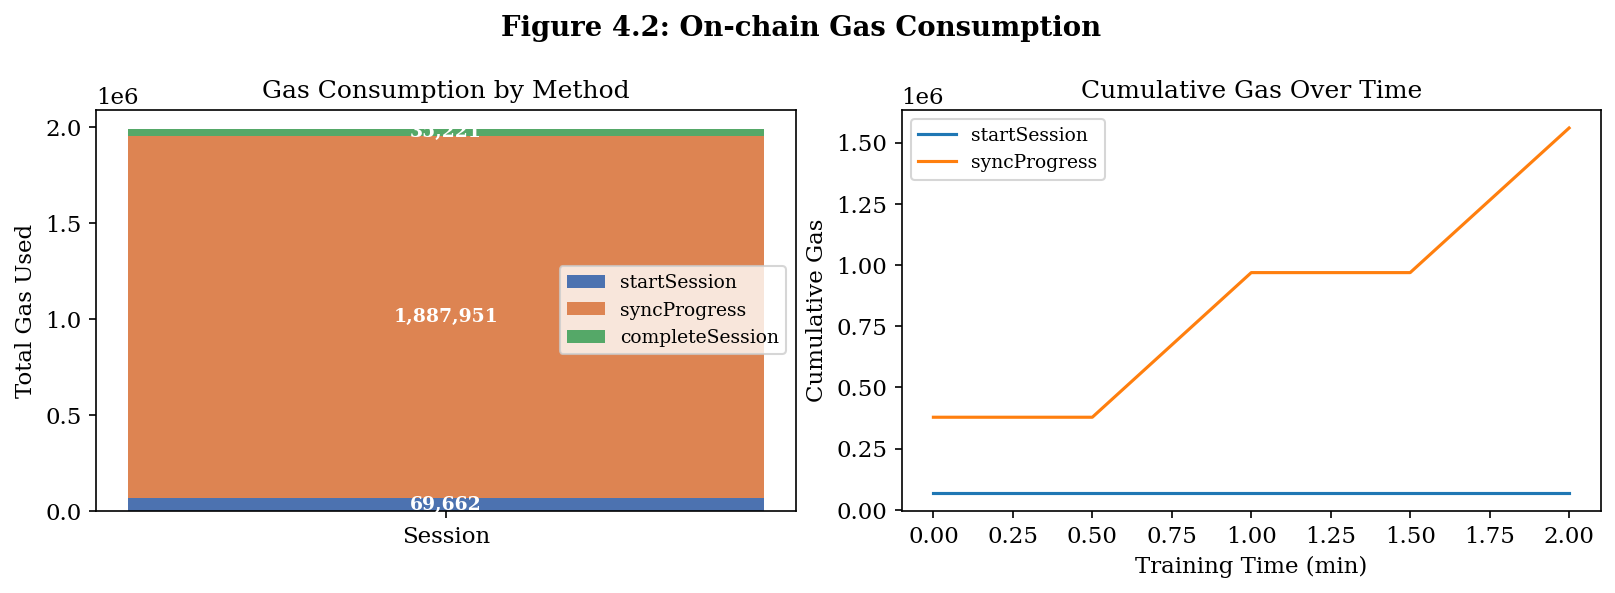

In [239]:
# Gas over time (cumulative counter)
gas_range = prom_range(
    f'blockchain_gas_used_total{{session_id="{SESSION_ID}"}}',
    TRAIN_START_TS, TRAIN_END_TS, step="30s"
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Left: stacked bar — total gas by method
ax    = axes[0]
bottom = 0
for i, (method, gas) in enumerate(zip(methods, gas_totals)):
    ax.bar(["Session"], [gas], bottom=bottom,
           color=COLORS[i], label=method, width=0.4)
    ax.text(0, bottom + gas / 2,
            f"{gas:,.0f}", ha="center", va="center",
            fontsize=9, color="white", fontweight="bold")
    bottom += gas
ax.set_ylabel("Total Gas Used")
ax.set_title("Gas Consumption by Method")
ax.legend(fontsize=9)

# Right: cumulative gas over time
ax2 = axes[1]
if gas_range:
    for series in gas_range:
        method_label = series["metric"].get("method", "total")
        vals  = series["values"]
        t0_   = float(vals[0][0])
        ts_   = [(float(v[0]) - t0_) / 60 for v in vals]
        gs_   = [float(v[1]) for v in vals]
        ax2.plot(ts_, gs_, linewidth=1.5, label=method_label)
ax2.set_xlabel("Training Time (min)")
ax2.set_ylabel("Cumulative Gas")
ax2.set_title("Cumulative Gas Over Time")
ax2.legend(fontsize=9)

fig.suptitle("Figure 4.2: On-chain Gas Consumption", fontweight="bold")
plt.tight_layout()
fig.savefig("fig4-2_gas.pdf", bbox_inches="tight")
plt.show()

## 5. Atomic Consistency & Fault Recovery

**Method**: Inject faults via `/debug/inject-fault` between blockchain anchor and OrbitDB write.  
Two fault types: `process_crash` (immediate exception) and `network_partition` (10 s timeout).  
After each injection, restart the controller and verify that `recoverOrphanTxs` restores the record.  
Idempotency is verified by triggering recovery twice and checking for duplicate entries.

**Target**: 100% recovery rate, 0 duplicate records

In [224]:
import os

ORPHAN_LOG    = f"{TOP_DIR}/audit-controller/orphan-txs.log"
RECOVERED_LOG = f"{TOP_DIR}/audit-controller/orphan-txs.recovered.log"

TEST_SESSION_ID = f"test-fault-injection-{int(time.time())}"
print(f"Test session ID: {TEST_SESSION_ID}")

def arm_fault(fault_type):
    return ctrl("/debug/inject-fault", method="POST",
                json={"fault_type": fault_type, "target": "orbitdb_write"})

def count_orphans():
    if not os.path.exists(ORPHAN_LOG):
        return 0
    with open(ORPHAN_LOG) as f:
        return sum(1 for l in f if l.strip())

def count_recovered():
    if not os.path.exists(RECOVERED_LOG):
        return 0
    with open(RECOVERED_LOG) as f:
        return sum(1 for l in f if l.strip())

def start_test_session():
    """Establish an independent test session that is 
    completely isolated from the real training data."""
    packet = {
        "packet": {
            "type": "session",
            "action": "start",
            "session_id": TEST_SESSION_ID,
            "payload": {
                "dataset_name": "fault-injection-test",
                "dataset_merkle_root": random_hex(),
                "dataset_cid": "bafytest000000000000000000000000000",
                "dataset_version": "v0.0",
                "hyperparams": {
                    "epochs": 1,
                    "batch_size": 64,
                    "step_interval": 100,
                    "lr": 0.01
                }
            }
        },
        "packet_hash": random_hex()
    }
    return ctrl("/audit/packet", method="POST", json=packet)

def send_dummy_packet():
    """Send a false step packet and use TEST_SESSION_ID
    instead of the actual SESSION_ID"""
    packet = {
        "packet": {
            "type": "step",
            "action": "",
            "session_id": TEST_SESSION_ID,
            "payload": {
                "id": 99999,
                "metrics": {"loss": 0.123}
            },
            "prev_hash": "0x" + "0" * 64,
        },
        "packet_hash": random_hex()
    }
    try:
        return ctrl("/audit/packet", method="POST", json=packet)
    except Exception as e:
        return {"error": str(e)}

def get_test_session_step_count():
    """Obtain the number of step packets in the test
    session for the purpose of ensuring idempotency."""
    try:
        cov = ctrl(f"/audit/session/{TEST_SESSION_ID}/coverage")
        return cov.get("captured_step_packets", 0)
    except Exception:
        # The coverage endpoint requires the presence of the session start packet.
        # Since the test session has been established, it should function normally.
        return 0

Test session ID: test-fault-injection-1778932085


In [225]:

print("Starting test session...")
start_result = start_test_session()
print(f"Test session started: {start_result}")

FAULT_TYPES = ["process_crash", "network_partition"]
ROUNDS_EACH = 3   # 3 rounds × 2 fault types = 6 total

recovery_results = []

for fault_type in FAULT_TYPES:
    for round_num in range(1, ROUNDS_EACH + 1):
        label = f"{fault_type} round {round_num}"
        print(f"\n{'─'*55}")
        print(f"Fault injection: {label}")

        # Step 1: arm the fault
        arm_result = arm_fault(fault_type)
        print(f"  Armed          : {arm_result}")

        # Step 2: send dummy packet
        # The blockchain anchor will succeed, while the write operation
        # of OrbitDB will fail due to injection errors.
        orphans_before = count_orphans()
        send_result = send_dummy_packet()
        print(f"  Packet sent    : {send_result}")

        orphans_after = count_orphans()
        orphans_generated = orphans_after - orphans_before
        print(f"  Orphans generated: {orphans_generated}")

        # Step 3: Waiting for fs.watch to trigger automatic recovery
        # network_partition requires a 10-second timeout period,
        # providing an additional buffer time.
        wait_secs = 15 if fault_type == "network_partition" else 5
        print(f"  Waiting {wait_secs}s for auto-recovery (fs.watch)...")
        time.sleep(wait_secs)

        orphans_remaining = count_orphans()
        recovered_count   = count_recovered()
        orphans_recovered = orphans_generated - orphans_remaining
        recovery_ok       = orphans_remaining == 0

        print(f"  Orphans remaining : {orphans_remaining}")
        print(f"  Recovery log lines: {recovered_count}")
        print(f"  Recovery status   : {'OK ✓' if recovery_ok else 'PENDING ✗'}")

        # Step 4: Idempotence verification
        # Record the current step count, trigger the recovery process again,
        # and confirm that no duplicate records are generated.
        entries_before = get_test_session_step_count()

        # Trigger fs.watch to execute recoverOrphanTxs again
        # by using the "touch orphan log" command
        # At this point, the log is empty (or non-existent), 
        # and the recovery logic should be a null operation.
        with open(ORPHAN_LOG, "a") as f:
            pass
        time.sleep(3)

        entries_after = get_test_session_step_count()
        duplicates    = max(entries_after - entries_before, 0)
        idempotent    = duplicates == 0

        print(f"  Idempotency check : before={entries_before}, after={entries_after}, duplicates={duplicates}")
        print(f"  Idempotent        : {'YES ✓' if idempotent else 'NO ✗'}")

        recovery_results.append({
            "fault_type":        fault_type,
            "round":             round_num,
            "orphans_generated": orphans_generated,
            "orphans_recovered": orphans_recovered,
            "orphans_remaining": orphans_remaining,
            "recovery_ok":       recovery_ok,
            "duplicates":        duplicates,
            "idempotent":        idempotent,
        })

df_recovery = pd.DataFrame(recovery_results)
print(f"\n{'='*55}")
print(df_recovery.to_string(index=False))

recovery_rate   = df_recovery["recovery_ok"].mean() * 100
idempotent_rate = df_recovery["idempotent"].mean() * 100
total_orphans   = df_recovery["orphans_generated"].sum()
total_recovered = df_recovery["orphans_recovered"].sum()

print(f"\nTotal orphans generated : {total_orphans}")
print(f"Total orphans recovered : {total_recovered}")
print(f"Recovery rate           : {recovery_rate:.1f}%  (target: 100%)")
print(f"Idempotency rate        : {idempotent_rate:.1f}%  (target: 100%, 0 duplicates)")
print(f"Overall result          : {'PASS ✓' if recovery_rate == 100 and idempotent_rate == 100 else 'FAIL ✗'}")

Starting test session...
Test session started: {'status': 'success', 'tx_hash': '0xcb219eedf2b540c596bd56f1397ae0ed0f885b54ea2154999d4448a304d37282'}

───────────────────────────────────────────────────────
Fault injection: process_crash round 1
  Armed          : {'status': 'fault armed', 'fault_type': 'process_crash', 'target': 'orbitdb_write'}
  Packet sent    : {'status': 'partial', 'tx_hash': '0xa280136d3cb6cdd989115a6bb1945a826e0ec230bbf14ecdb8f0619ce25eec9c'}
  Orphans generated: 1
  Waiting 5s for auto-recovery (fs.watch)...
  Orphans remaining : 0
  Recovery log lines: 77
  Recovery status   : OK ✓
  Idempotency check : before=1, after=1, duplicates=0
  Idempotent        : YES ✓

───────────────────────────────────────────────────────
Fault injection: process_crash round 2
  Armed          : {'status': 'fault armed', 'fault_type': 'process_crash', 'target': 'orbitdb_write'}
  Packet sent    : {'status': 'partial', 'tx_hash': '0xbe27b6c598f563c6f40cb5da30a571ac35fc384c1738372f8

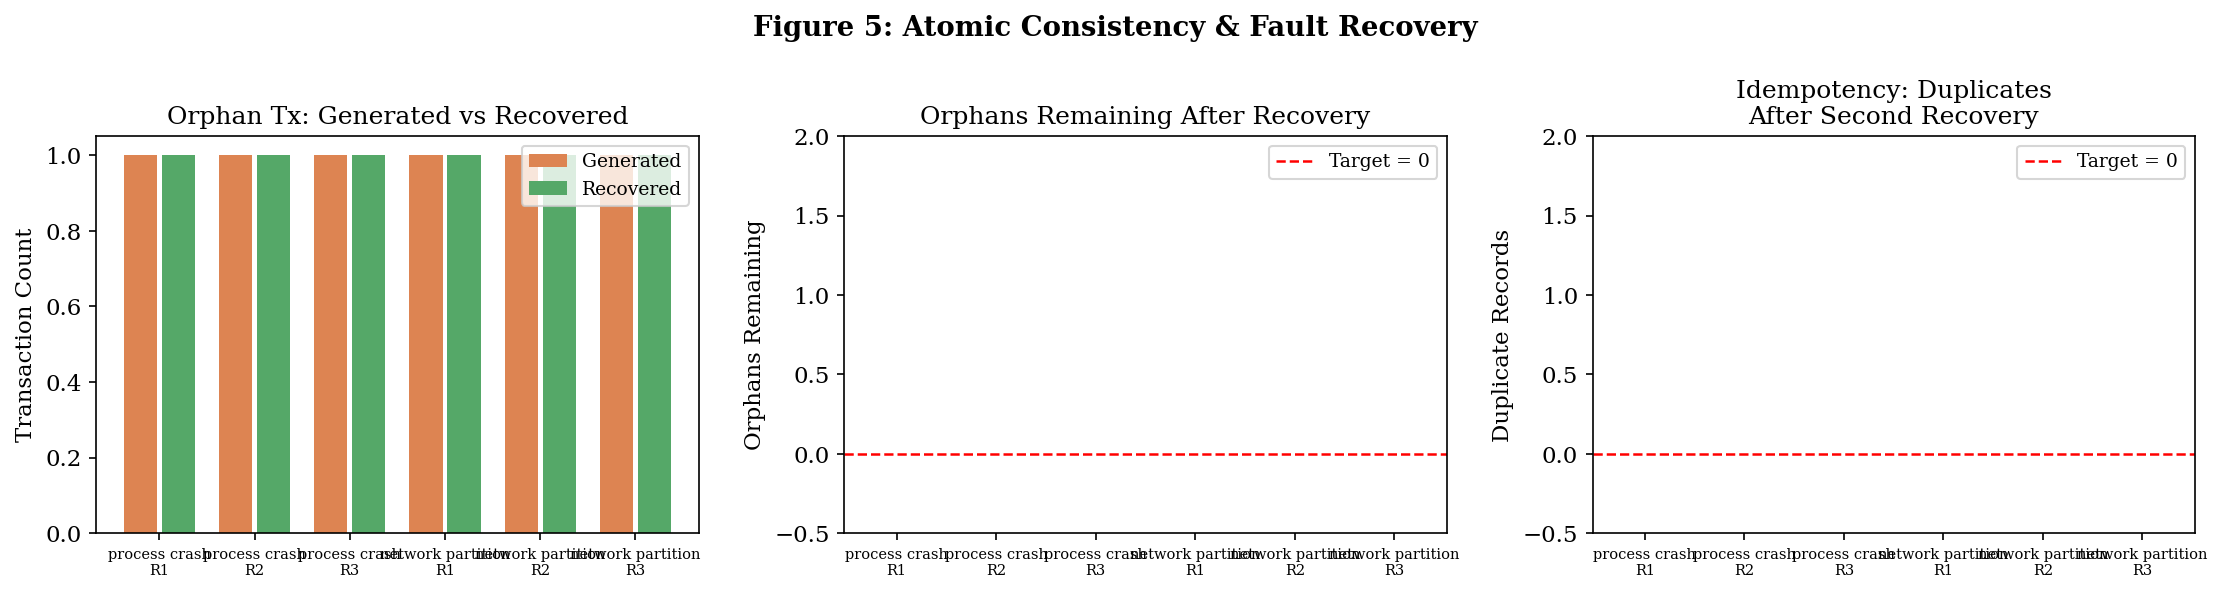

In [240]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

fault_labels = [f"{r['fault_type'].replace('_', ' ')}\nR{r['round']}"
                for _, r in df_recovery.iterrows()]
x = np.arange(len(fault_labels))

# Left: Generated vs Recovered
ax = axes[0]
ax.bar(x - 0.2, df_recovery["orphans_generated"], width=0.35,
       color=COLORS[1], label="Generated")
ax.bar(x + 0.2, df_recovery["orphans_recovered"], width=0.35,
       color=COLORS[2], label="Recovered")
ax.set_xticks(x)
ax.set_xticklabels(fault_labels, fontsize=7)
ax.set_ylabel("Transaction Count")
ax.set_title("Orphan Tx: Generated vs Recovered")
ax.legend(fontsize=9)

# Middle: Orphans Remaining After Recovery (target = 0)
ax2 = axes[1]
bar_colors2 = [COLORS[2] if v == 0 else COLORS[3]
               for v in df_recovery["orphans_remaining"]]
ax2.bar(x, df_recovery["orphans_remaining"], color=bar_colors2, width=0.5)
ax2.axhline(0, color="red", linestyle="--", linewidth=1.2, label="Target = 0")
ax2.set_xticks(x)
ax2.set_xticklabels(fault_labels, fontsize=7)
ax2.set_ylabel("Orphans Remaining")
ax2.set_title("Orphans Remaining After Recovery")
ax2.set_ylim(-0.5, max(df_recovery["orphans_remaining"].max() + 1, 2))
ax2.legend(fontsize=9)

# Right: Duplicates after second recovery (target = 0)
ax3 = axes[2]
dup_colors = [COLORS[2] if v == 0 else COLORS[3]
              for v in df_recovery["duplicates"]]
ax3.bar(x, df_recovery["duplicates"], color=dup_colors, width=0.5)
ax3.axhline(0, color="red", linestyle="--", linewidth=1.2, label="Target = 0")
ax3.set_xticks(x)
ax3.set_xticklabels(fault_labels, fontsize=7)
ax3.set_ylabel("Duplicate Records")
ax3.set_title("Idempotency: Duplicates\nAfter Second Recovery")
ax3.set_ylim(-0.5, max(df_recovery["duplicates"].max() + 1, 2))
ax3.legend(fontsize=9)

fig.suptitle("Figure 5: Atomic Consistency & Fault Recovery", fontweight="bold")
plt.tight_layout()
fig.savefig("fig5_consistency.pdf", bbox_inches="tight")
plt.show()

## 6. Audit Coverage (RQ2)

**Source**: `/audit/session/:id/coverage`  
**Target**: Step coverage ratio = 1.0, Epoch coverage ratio = 1.0

In [245]:
cov = ctrl(f"/audit/session/{SESSION_ID}/coverage")
print(json.dumps(cov, indent=2))

step_cov  = cov.get("step_coverage_ratio")
epoch_cov = cov.get("epoch_coverage_ratio")

print(f"\nStep  coverage : {step_cov:.4f}  (target: 1.0) — {'PASS ✓' if step_cov and step_cov == 1.0 else 'CHECK'}")
print(f"Epoch coverage : {epoch_cov:.4f}  (target: 1.0) — {'PASS ✓' if epoch_cov and epoch_cov == 1.0 else 'CHECK'}")

{
  "session_id": "session-1778931083-836e067c",
  "captured_step_packets": 47,
  "captured_epoch_packets": 10,
  "theoretical_epoch_count": 10,
  "theoretical_step_captures": 47,
  "step_coverage_ratio": 1,
  "epoch_coverage_ratio": 1
}

Step  coverage : 1.0000  (target: 1.0) — PASS ✓
Epoch coverage : 1.0000  (target: 1.0) — PASS ✓


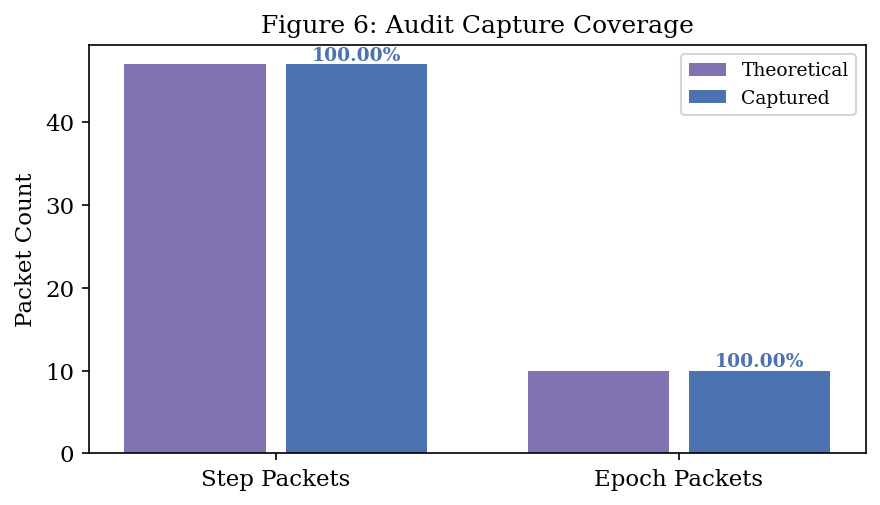

In [241]:
fig, ax = plt.subplots(figsize=(6, 3.5))

categories = ["Step Packets", "Epoch Packets"]
captured   = [cov["captured_step_packets"], cov["captured_epoch_packets"]]
theoretical= [cov["theoretical_step_captures"], cov["theoretical_epoch_count"]]

x = np.arange(len(categories))
ax.bar(x - 0.2, theoretical, width=0.35, color=COLORS[4], label="Theoretical")
ax.bar(x + 0.2, captured,    width=0.35, color=COLORS[0], label="Captured")

for i, (cap, theo) in enumerate(zip(captured, theoretical)):
    ratio = cap / theo if theo > 0 else 0
    ax.text(i + 0.2, cap + 0.5, f"{ratio:.2%}",
            ha="center", fontsize=9, color=COLORS[0], fontweight="bold")

ax.set_xticks(x)
ax.set_xticklabels(categories)
ax.set_ylabel("Packet Count")
ax.set_title("Figure 6: Audit Capture Coverage")
ax.legend(fontsize=9)
plt.tight_layout()
fig.savefig("fig6_coverage.pdf", bbox_inches="tight")
plt.show()

## Summary Table

Consolidated results across all evaluation criteria.

In [247]:
summary_rows = [
    {
        "Criterion": "Training overhead",
        "Target": "< 5%",
        "Measured": f"{overhead_pct:+.2f}%",
        "Result": "PASS" if overhead_pct < 5 else "FAIL"
    },
    {
        "Criterion": "Audit effectiveness",
        "Target": "100% tampering detection",
        "Measured": f"{detection_rate:.1f}%",
        "Result": "PASS" if detection_rate == 100 else "FAIL"
    },
    {
        "Criterion": "Verification Response",
        "Target": "< 2000 ms",
        "Measured": f"P99 max {max(r['P99 (ms)'] for _, r in df_verify.iterrows())}ms",
        "Result": "PASS" if all(r["P99 (ms)"] < 2000 for _, r in df_verify.iterrows()) else "FAIL"
    },
    {
        "Criterion": "Storage linear growth",
        "Target": "R² > 0.99",
        "Measured": f"R²={r_value**2:.5f}",
        "Result": "PASS" if r_value**2 > 0.99 else "FAIL"
    },
    {
        "Criterion": "Fault recovery rate",
        "Target": "100%",
        "Measured": f"{recovery_rate:.1f}%",
        "Result": "PASS" if recovery_rate == 100 else "FAIL"
    },
    {
        "Criterion": "Idempotency (0 duplicates)",
        "Target": "0 duplicates",
        "Measured": f"{int(df_recovery['duplicates'].sum())} total",
        "Result": "PASS" if df_recovery['duplicates'].sum() == 0 else "FAIL"
    },
    {
        "Criterion": "Step capture coverage",
        "Target": "1.0 (100%)",
        "Measured": f"{step_cov:.2%}" if step_cov else "N/A",
        "Result": "PASS" if step_cov and step_cov == 1.0 else "FAIL"
    },
    {
        "Criterion": "Epoch capture coverage",
        "Target": "1.0 (100%)",
        "Measured": f"{epoch_cov:.2%}" if epoch_cov else "N/A",
        "Result": "PASS" if epoch_cov and epoch_cov == 1.0 else "FAIL"
    },
]

df_summary = pd.DataFrame(summary_rows)
print(df_summary.to_string(index=False))

pass_count = (df_summary["Result"] == "PASS").sum()
total      = len(df_summary)
print(f"\n{pass_count}/{total} criteria passed")

                 Criterion                   Target      Measured Result
         Training overhead                     < 5%        +4.48%   PASS
       Audit effectiveness 100% tampering detection        100.0%   PASS
     Verification Response                < 2000 ms P99 max 248ms   PASS
     Storage linear growth                R² > 0.99    R²=0.99984   PASS
       Fault recovery rate                     100%        100.0%   PASS
Idempotency (0 duplicates)             0 duplicates       0 total   PASS
     Step capture coverage               1.0 (100%)       100.00%   PASS
    Epoch capture coverage               1.0 (100%)       100.00%   PASS

8/8 criteria passed


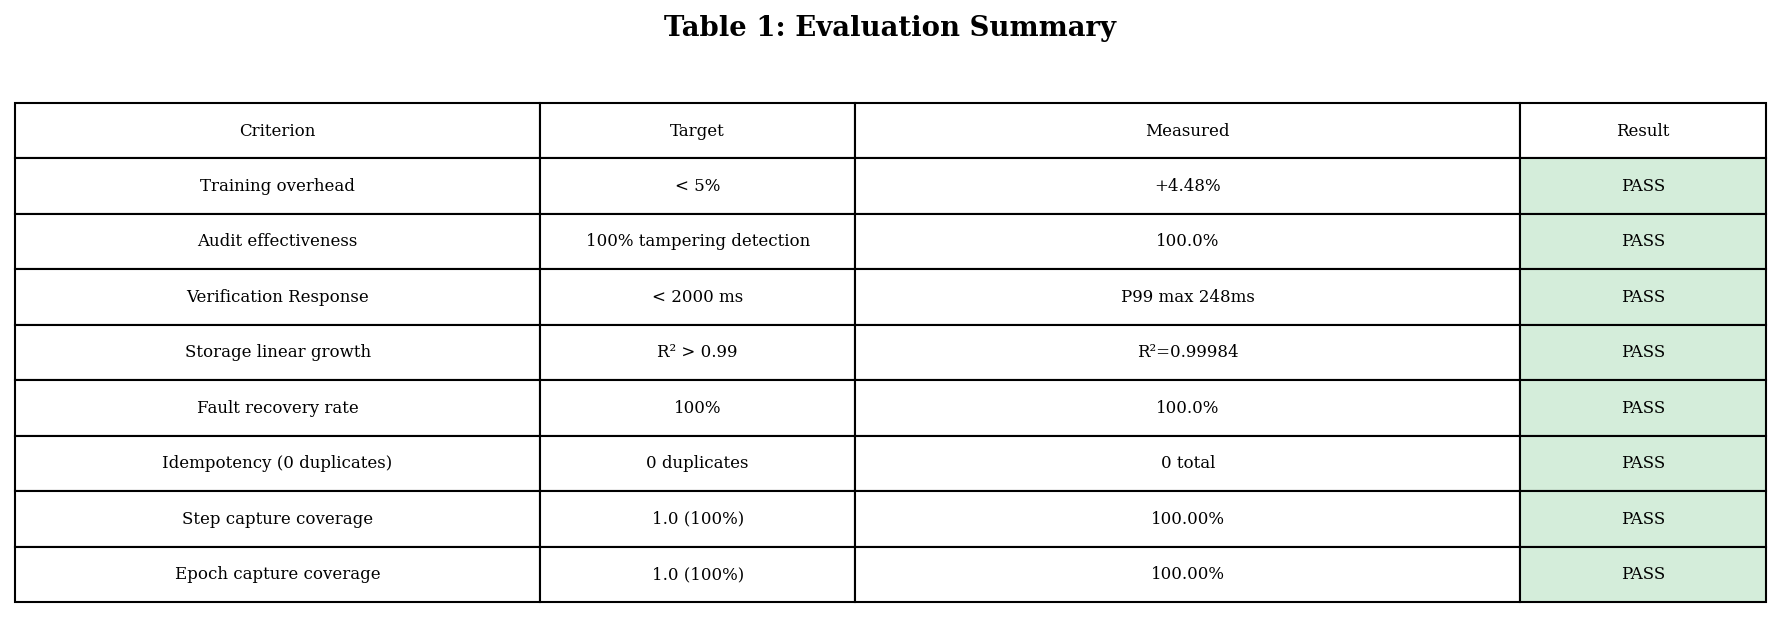

In [248]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.axis("off")

cell_colors = [
    ["white"] * 3 + ["#d4edda" if r == "PASS" else "#f8d7da"]
    for r in df_summary["Result"]
]

def wrap_cell(text, max_len=40):
    text = str(text)
    if len(text) <= max_len:
        return text
    parts = text.split(", ")
    lines, current = [], ""
    for part in parts:
        if len(current) + len(part) > max_len:
            lines.append(current.rstrip(", "))
            current = part + ", "
        else:
            current += part + ", "
    if current:
        lines.append(current.rstrip(", "))
    return "\n".join(lines)

cell_text = [
    [wrap_cell(v) for v in row]
    for row in df_summary.values
]

table = ax.table(
    cellText  = cell_text,
    colLabels = df_summary.columns,
    cellLoc   = "center",
    loc       = "center",
    cellColours = cell_colors
)
table.auto_set_font_size(False)
table.set_fontsize(8)
table.scale(1, 2.2)

col_widths = [0.30, 0.18, 0.38, 0.14]
for (row, col), cell in table.get_celld().items():
    cell.set_width(col_widths[col] if col < len(col_widths) else 0.2)
    cell.set_text_props(wrap=True)

fig.suptitle("Table 1: Evaluation Summary", fontweight="bold", y=1.02)
plt.tight_layout()
fig.savefig("table1_summary.pdf", bbox_inches="tight")
plt.show()